# Benchmark — Milvus index types

Compares **HNSW**, **IVF_FLAT** and **IVF_PQ** on the Wongnai vectors, with **FLAT** as the
exact baseline and **AUTOINDEX** as what the deployed collection was actually created with.

Five measurements per index: **accuracy** (recall against exact search), **latency**,
**throughput (QPS)**, **index build time** and **memory cost**. Every result goes to a new
per-run directory under `data/eval/runs/` and to MLflow.

Method, definitions and the results tables: [`benchmark_index_types.md`](../docs/part_1/benchmark_index_types.md).

## Run sheet — read this before running anything

| Step | Do | Stop if |
|---|---|---|
| **R0** services | `docker start data_server_etcd data_server_minio data_server_postgres data_server_milvus data_server_mlflow`. Unlike `compose up`, it can't recreate a container. Leave Elasticsearch, Kibana, Neo4j and n8n **off** | Any of the five doesn't reach `(healthy)` in `docker ps` |
| **R1** preflight | Check `MODE = "smoke"`, then run down to and including the **preflight** cell. It creates nothing except the MLflow experiment, if it's new, and one probe run, which it deletes | It raises. Nothing has been built yet, so fix the cause and re-run |
| **R2** smoke | Run all remaining cells. Results are tagged `comparable=false` | The FLAT sanity check, the Milvus restart check, the QPS error check or MLflow verification fails. Any of these means the numbers cannot be trusted |
| **R3** full | **Restart the kernel**, set `MODE = "full"`, close other heavy applications, run all | Same as R2 |
| **R4** record | Copy the tables printed by the last cell into the doc | |

**What this notebook changes on the server**

- Creates the database `restaurant_bench_db`, and drops and recreates the collection inside it.
- **Releases every loaded collection** so its memory cannot pollute the readings. That
  includes `wongnai_review_coll`, so **`/query` will not work during a run**. The
  **restore** cell loads them back from `pre_state.json`. **If a run fails, still run it.**
- Restarts the `data_server_milvus` container once per memory cycle: up to 3 times per config.
- It never writes to, or drops, anything outside `restaurant_bench_db`.

**Rules**

- **Keep the PC plugged in with the lid open.** Milvus exits if the PC sleeps past its etcd
  lease. The notebook blocks Windows idle sleep during a run and stops if Milvus restarts on its
  own, but closing the lid can still sleep the PC. If a run stops this way, run the **restore**
  cell and start a new run.
- **Never re-run the run-directory cell mid-run.** It mints a new `RUN_SLUG` and `OUT_DIR`
  (`exist_ok=False`). Restart the kernel instead.
- **Do not run k6, an ingest or anything else against Milvus during a run.** Everything
  shares the laptop's 4 cores.
- **Spend:** embedding the 6,195 held-out reviews once, about $0.065, during the first run
  (the smoke run). Later runs use the cache. The cell prints the cost before it embeds.
- **If the kernel dies during the MLflow step:** the results are safe in `OUT_DIR`. Run
  through the **run config** cell, set `OUT_DIR = Path("data/eval/runs/<slug>")`, then run
  the **log to MLflow** cell. It reads only from disk.

In [1]:
# ---- working directory ----
# Everything below imports `app` and reads data/ relative to the repo root.
import os
from pathlib import Path

if Path.cwd().name == "notebook":
    os.chdir("..")

print(Path.cwd())

k:\Gen AI\project\restaurant-rag


In [2]:
# ---- run config ----
# No side effects: nothing is created or written until the run-directory cell.
import ctypes
import hashlib
import importlib.metadata as md
import json
import platform
import random
import re
import subprocess
import sys
import tempfile
import threading
import time
import urllib.request
from datetime import datetime, timezone

import boto3
import matplotlib.pyplot as plt
import mlflow
import numpy as np
import pandas as pd
import tiktoken
from botocore.client import Config
from dotenv import load_dotenv
from mlflow.tracking import MlflowClient
from pymilvus import DataType, MilvusClient, connections, utility

from app.config import BASE_DIR, settings
from app.services.milvus_service import EMBED_BATCH_SIZE
from app.services.openai_service import MAX_EMBED_TOKENS, embed_texts
from evaluation.heldout import SAMPLE_SEED, load_test_reviews, load_train_texts

# MLflow 3 prints a "run finished" line containing an emoji when a run ends. On
# Windows' cp1252 console that raises UnicodeEncodeError after the metrics are
# already logged, so force UTF-8 and let the run close cleanly.
if hasattr(sys.stdout, "reconfigure"):
    sys.stdout.reconfigure(encoding="utf-8", errors="replace")
    sys.stderr.reconfigure(encoding="utf-8", errors="replace")

# ------------------------------------------------------------------ mode ----
MODE = "full"      # "smoke" proves the harness; only "full" produces results.

MODES = {
    "smoke": {"build_repeats": 1, "latency_repeats": 1, "concurrency": [2],
              "select_concurrency": 2, "qps_seconds": 3, "settle_seconds": 5,
              "all_points": False, "memory_cycles": 1, "heldout_limit": 500,
              "timing_queries": 100},
    "full":  {"build_repeats": 3, "latency_repeats": 2, "concurrency": [1, 4, 8],
              "select_concurrency": 4, "qps_seconds": 15, "settle_seconds": 30,
              "all_points": True, "memory_cycles": 3, "heldout_limit": None,
              "timing_queries": 1000},
}
PLAN = MODES[MODE]

# ----------------------------------------------------------------- source ----
# Read-only: vectors are copied out of this collection, never written back.
SOURCE_DATABASE = "restaurant_db"
SOURCE_COLLECTION = "wongnai_review_coll"
EXPECTED_ROWS = 40_000

# ------------------------------------------------------------------ bench ----
BENCH_DATABASE = "restaurant_bench_db"
BENCH_COLLECTION = "index_types"
INDEX_NAME = "vector"
METRIC_TYPE = settings.milvus_metric_type
INSERT_BATCH = 1000

assert BENCH_DATABASE != SOURCE_DATABASE, "the bench must never share the source's database"

# -------------------------------------------------------------- what to test ----
TOP_K = settings.top_k      # what production asks for; every timed search uses it
RECALL_AT = (5, 10)
RECALL_TARGETS = (0.70, 0.80, 0.90, 0.95)     # fixed before any result exists; doc section 3.5
RECALL_KEY = f"recall_at_{TOP_K}"
RECALL_BATCH = 100          # queries per recall request
TIE_EPS = 1e-6              # float32 dot products agree to about this
assert TOP_K in RECALL_AT, f"TOP_K={TOP_K} has no recall column; add it to RECALL_AT"

# 4 * sqrt(40,000), the usual starting point for nlist.
NLIST = 800
IVF_NPROBE = [1, 4, 8, 16, 32, 64, 128, 256]

CONFIGS = [
    # First on purpose: the sanity check on FLAT stops a broken harness early.
    {"name": "FLAT", "index_type": "FLAT", "build": {},
     "search_param": None, "search_values": [None]},
    # What pymilvus's quick-setup create_collection requests, so what is deployed.
    {"name": "AUTOINDEX", "index_type": "AUTOINDEX", "build": {},
     "search_param": None, "search_values": [None]},
    # ef must be >= the limit, and the recall pass searches at max(RECALL_AT).
    {"name": "HNSW-M16-efc200", "index_type": "HNSW",
     "build": {"M": 16, "efConstruction": 200},
     "search_param": "ef", "search_values": [10, 16, 32, 64, 128, 256, 512]},
    {"name": "IVF_FLAT-nlist800", "index_type": "IVF_FLAT",
     "build": {"nlist": NLIST},
     "search_param": "nprobe", "search_values": IVF_NPROBE},
    # m must divide 1536. Two values because m sets how much accuracy PQ can reach.
    {"name": "IVF_PQ-nlist800-m96", "index_type": "IVF_PQ",
     "build": {"nlist": NLIST, "m": 96, "nbits": 8},
     "search_param": "nprobe", "search_values": IVF_NPROBE},
    {"name": "IVF_PQ-nlist800-m192", "index_type": "IVF_PQ",
     "build": {"nlist": NLIST, "m": 192, "nbits": 8},
     "search_param": "nprobe", "search_values": IVF_NPROBE},
]


def search_points(config: dict) -> list:
    """The search-parameter values this mode sweeps for one config."""
    values = config["search_values"]
    return values if PLAN["all_points"] or len(values) == 1 else [values[0], values[-1]]


def qps_by_target(h2h: pd.DataFrame, qps_column: str) -> pd.DataFrame:
    """One row per config, one column per target. Empty where it was not reached."""
    order = h2h["config"].drop_duplicates()
    return (h2h[h2h["reached"]]
            .pivot(index="config", columns="recall_target", values=qps_column)
            .reindex(order)
            .rename(columns=lambda t: f"{t:.2f}")
            .reset_index())


def keep_awake(on: bool) -> None:
    """Block Windows' idle sleep during a run, because Milvus exits if the PC sleeps.

    Lives in this cell so the restore cell can clear it from a fresh kernel. Closing the
    lid can still sleep the PC.
    """
    es_continuous, es_system_required = 0x80000000, 0x00000001
    ctypes.windll.kernel32.SetThreadExecutionState(
        es_continuous | (es_system_required if on else 0))


# ------------------------------------------------------------------ files ----
# test_file.csv minus rows that exactly match an indexed review (data/eval/README.md).
EXPECTED_HELDOUT = 6195
TIMING_SAMPLE = 1000        # drawn once with SAMPLE_SEED; a smoke run takes its first rows
CACHE_DIR = Path("data/eval/index_bench")

# ---------------------------------------------------------------- services ----
MILVUS_CONTAINER = "data_server_milvus"
MILVUS_HEALTH_URL = "http://localhost:9091/healthz"
# Everything R0 starts. Anything else running competes for the same 4 cores.
EXPECTED_CONTAINERS = {"data_server_milvus", "data_server_etcd", "data_server_minio",
                       "data_server_postgres", "data_server_mlflow"}

MLFLOW_TRACKING_URI = os.getenv("MLFLOW_TRACKING_URI", "http://localhost:5000")
MLFLOW_EXPERIMENT = "restaurant_rag/phase_1_index_types"

# Milvus keeps index files here. MinIO credentials live with the compose stack:
# k:/Gen AI/project/restaurant-rag -> parents[2] is k:/
DATA_SERVER_ENV = BASE_DIR.parents[2] / "MLOps" / "data_server" / ".env"
load_dotenv(DATA_SERVER_ENV)
MINIO_ENDPOINT = "http://localhost:9000"
MILVUS_BUCKET = "a-bucket"
INDEX_FILES_PREFIX = "files/index_files/"

points = sum(len(search_points(c)) for c in CONFIGS)
print(f"mode {MODE}: {len(CONFIGS)} configs, {points} search points, "
      f"concurrency {PLAN['concurrency']}, {PLAN['qps_seconds']} s per QPS window")

k:\Gen AI\project\restaurant-rag\restaurant_rag_venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


mode full: 6 configs, 33 search points, concurrency [1, 4, 8], 15 s per QPS window


In [3]:
# ---- helpers ----
_TO_MB = {"B": 1 / 1024**2, "KiB": 1 / 1024, "MiB": 1, "GiB": 1024, "TiB": 1024**2,
          "kB": 1e3 / 1024**2, "MB": 1e6 / 1024**2, "GB": 1e9 / 1024**2}


def to_mb(text: str) -> float:
    """Parse one `docker stats` size such as `1.5GiB`."""
    match = re.fullmatch(r"\s*([\d.]+)\s*([A-Za-z]+)\s*", text)
    return float(match[1]) * _TO_MB[match[2]]


def docker_stats() -> dict:
    """Milvus container memory and CPU. Takes a second or two per call."""
    out = subprocess.run(
        ["docker", "stats", "--no-stream", "--format", "{{.MemUsage}}|{{.CPUPerc}}",
         MILVUS_CONTAINER],
        capture_output=True, text=True, check=True, timeout=60,
    ).stdout.strip()
    usage, cpu = out.split("|")
    used, limit = usage.split("/")
    return {"mem_mb": to_mb(used), "limit_mb": to_mb(limit), "cpu_pct": float(cpu.rstrip("%"))}


def median_mem_mb(samples: int = 3) -> float:
    return float(np.median([docker_stats()["mem_mb"] for _ in range(samples)]))


def cgroup_peak_mb() -> float:
    """The container's memory high-water mark since it started, NaN if unavailable.

    Catches spikes that docker_stats' slow sampling misses, but it counts page cache,
    which docker_stats leaves out. So it is an upper bound, reported in its own column.
    """
    result = subprocess.run(
        ["docker", "exec", MILVUS_CONTAINER, "cat", "/sys/fs/cgroup/memory.peak"],
        capture_output=True, text=True, timeout=30,
    )
    try:
        return int(result.stdout.strip()) / 1024**2
    except ValueError:
        return float("nan")


def minio_client():
    return boto3.client(
        "s3", endpoint_url=MINIO_ENDPOINT,
        aws_access_key_id=os.environ["MINIO_ACCESS_KEY"],
        aws_secret_access_key=os.environ["MINIO_SECRET_KEY"],
        config=Config(signature_version="s3v4"), region_name="us-east-1",
    )


def index_file_sizes() -> dict:
    """Every object under Milvus's index prefix, key -> bytes.

    Index files are keyed by build id, so one build's size is the set of keys
    that appeared during it. Summing the whole prefix would also count old
    builds waiting for GC, which is what inflates benchmark.md section 1.2.
    """
    pages = minio_client().get_paginator("list_objects_v2").paginate(
        Bucket=MILVUS_BUCKET, Prefix=INDEX_FILES_PREFIX)
    return {obj["Key"]: obj["Size"] for page in pages for obj in page.get("Contents", [])}


def bench_client() -> MilvusClient:
    return MilvusClient(uri=settings.milvus_uri, db_name=BENCH_DATABASE)


def restart_milvus(timeout: float = 300.0) -> MilvusClient:
    """Restart Milvus so RAM is read from a process that has loaded nothing.

    The Go runtime keeps freed memory, so a release alone would leave one
    config's footprint inside the next config's baseline.
    """
    subprocess.run(["docker", "restart", MILVUS_CONTAINER],
                   check=True, capture_output=True, timeout=120)
    deadline = time.monotonic() + timeout
    while time.monotonic() < deadline:
        try:
            with urllib.request.urlopen(MILVUS_HEALTH_URL, timeout=5) as response:
                if response.status == 200:
                    client = bench_client()
                    client.list_collections()
                    return client
        except Exception:       # refused or not ready yet: both mean keep waiting
            pass
        time.sleep(2)
    raise TimeoutError(f"{MILVUS_CONTAINER} not healthy after {timeout:.0f} s")


def milvus_started_at() -> str:
    return subprocess.run(
        ["docker", "inspect", "--format", "{{.State.StartedAt}}", MILVUS_CONTAINER],
        capture_output=True, text=True, check=True, timeout=30,
    ).stdout.strip()


def check_no_restart(expected_start: str) -> None:
    """Stop if Milvus restarted on its own, because what was just measured can't be trusted.

    Milvus exits if the PC sleeps past its etcd lease, and the compose file's
    `restart: unless-stopped` brings it back. pymilvus retries failed calls, so a search
    can simply succeed, slowly, with nothing else to show for it.
    """
    if milvus_started_at() != expected_start:
        raise RuntimeError(f"{MILVUS_CONTAINER} restarted during a measurement. Run the "
                           "restore cell, keep the PC awake, and start a new run.")


def wait_for_index(client: MilvusClient, expected_rows: int,
                   timeout: float = 3600.0, poll: float = 0.25) -> dict:
    """Block until every row is indexed. `poll` is the build time's resolution."""
    deadline = time.monotonic() + timeout
    while time.monotonic() < deadline:
        info = client.describe_index(BENCH_COLLECTION, INDEX_NAME)
        if info["state"] == "Failed":
            raise RuntimeError(f"index build failed: {info}")
        if (info["state"] == "Finished" and info["pending_index_rows"] == 0
                and info["indexed_rows"] >= expected_rows):
            return info
        time.sleep(poll)
    raise TimeoutError(f"index not finished after {timeout:.0f} s")


def drop_index_if_any(client: MilvusClient) -> None:
    client.release_collection(BENCH_COLLECTION)
    if INDEX_NAME in client.list_indexes(BENCH_COLLECTION):
        client.drop_index(BENCH_COLLECTION, INDEX_NAME)


def build_once(client: MilvusClient, config: dict) -> tuple[float, float, dict]:
    """Build one index. Returns (seconds, MB of new index files, describe_index)."""
    drop_index_if_any(client)
    params = MilvusClient.prepare_index_params()
    params.add_index("vector", index_type=config["index_type"], index_name=INDEX_NAME,
                     metric_type=METRIC_TYPE, params=config["build"])

    before = index_file_sizes()
    started = time.perf_counter()
    client.create_index(BENCH_COLLECTION, params, sync=False)
    info = wait_for_index(client, N_ROWS)
    seconds = time.perf_counter() - started

    after = index_file_sizes()
    new_bytes = sum(size for key, size in after.items() if key not in before)
    return seconds, new_bytes / 1024**2, info


def load_and_measure(client: MilvusClient) -> dict:
    """Load the collection and read memory around it. Starts from a fresh process."""
    # A just-restarted server is still settling; its baseline would read low.
    time.sleep(PLAN["settle_seconds"])
    idle = median_mem_mb()

    samples, stop = [], threading.Event()

    def sampler():
        while not stop.is_set():
            samples.append(docker_stats()["mem_mb"])

    thread = threading.Thread(target=sampler, daemon=True)
    thread.start()
    started = time.perf_counter()
    client.load_collection(BENCH_COLLECTION, timeout=1800)
    load_seconds = time.perf_counter() - started
    stop.set()
    thread.join()

    time.sleep(PLAN["settle_seconds"])
    steady = median_mem_mb()
    peak = max(samples + [steady])

    return {"load_seconds": load_seconds, "ram_idle_mb": idle, "ram_steady_mb": steady,
            "ram_delta_mb": steady - idle, "ram_peak_delta_mb": peak - idle,
            "ram_cgroup_peak_mb": cgroup_peak_mb()}


def loaded_segments() -> dict:
    """What the query node holds. Segment count shapes every IVF and HNSW result."""
    alias = "index_bench"
    connections.connect(alias=alias, uri=settings.milvus_uri, db_name=BENCH_DATABASE)
    try:
        infos = utility.get_query_segment_info(BENCH_COLLECTION, using=alias)
    finally:
        connections.disconnect(alias)
    return {"segments": len(infos),
            "loaded_rows": sum(s.num_rows for s in infos),
            "segment_mem_mb": sum(s.mem_size for s in infos) / 1024**2}


def search_params_for(config: dict, value) -> dict:
    params = {} if config["search_param"] is None else {config["search_param"]: value}
    return {"metric_type": METRIC_TYPE, "params": params}


def recall_pass(client: MilvusClient, search_params: dict) -> dict:
    """Recall against exact search. Untimed, so accuracy and speed cannot interfere.

    Searches at max(RECALL_AT) once: ef and nprobe set the candidate pool, not the
    limit, so the top 5 of a limit-10 search is the limit-5 result.
    """
    results = []
    for start in range(0, len(RECALL_VECTORS), RECALL_BATCH):
        results.extend(client.search(
            collection_name=BENCH_COLLECTION,
            data=RECALL_VECTORS[start:start + RECALL_BATCH].tolist(), limit=max(RECALL_AT),
            anns_field="vector", search_params=search_params,
        ))

    metrics = {}
    for k in RECALL_AT:
        tolerant, strict = [], []
        for q, hits in enumerate(results):
            ids = np.array([hit["id"] for hit in list(hits)[:k]], dtype=np.int64)
            # Score the returned ids exactly: PQ's own distances are approximate.
            # Counting by score, not id, stops duplicate reviews (identical vectors,
            # arbitrary order) from reading as misses.
            exact = CORPUS_VECTORS[np.searchsorted(CORPUS_IDS, ids)] @ RECALL_VECTORS[q]
            tolerant.append(min(k, int((exact >= GT_KTH_SCORE[k][q] - TIE_EPS).sum())) / k)
            strict.append(len(set(ids.tolist()) & set(GT_IDS[q, :k].tolist())) / k)
        metrics[f"recall_at_{k}"] = float(np.mean(tolerant))
        metrics[f"recall_at_{k}_p10"] = float(np.percentile(tolerant, 10))
        metrics[f"recall_at_{k}_strict"] = float(np.mean(strict))
        # 95% margin of error on the mean, so a near-tie can be read as one.
        metrics[f"recall_at_{k}_moe95"] = float(
            1.96 * np.std(tolerant, ddof=1) / np.sqrt(len(tolerant)))
    return metrics


def latency_pass(client: MilvusClient, search_params: dict) -> dict:
    """One client, one query at a time. The first pass warms the path and is discarded."""
    def run_pass() -> list[float]:
        timings = []
        for vector in TIMING_LISTS:
            started = time.perf_counter()
            client.search(collection_name=BENCH_COLLECTION, data=[vector], limit=TOP_K,
                          anns_field="vector", search_params=search_params)
            timings.append((time.perf_counter() - started) * 1000)
        return timings

    run_pass()
    timings = [t for _ in range(PLAN["latency_repeats"]) for t in run_pass()]
    return {"latency_p50_ms": float(np.percentile(timings, 50)),
            "latency_p95_ms": float(np.percentile(timings, 95)),
            "latency_p99_ms": float(np.percentile(timings, 99)),
            "latency_samples": len(timings)}


# One process per simulated client. Threads would share the GIL, and pymilvus does
# real CPU work encoding each request, so the client could become the bottleneck.
# Passed to `python -c` because Windows' spawn cannot pickle a notebook function.
WORKER_SRC = r'''
import json, sys, time
import numpy as np
from pymilvus import MilvusClient

cfg = json.loads(sys.argv[1])
queries = np.load(cfg["query_file"]).tolist()
client = MilvusClient(uri=cfg["uri"], db_name=cfg["database"])
kwargs = dict(collection_name=cfg["collection"], limit=cfg["top_k"],
              anns_field="vector", search_params=cfg["search_params"])

client.search(data=[queries[0]], **kwargs)     # connect before the start signal
print("ready", flush=True)
sys.stdin.readline()

timings, errors, first_error, i = [], 0, None, cfg["offset"]
started = time.perf_counter()
deadline = started + cfg["seconds"]
while time.perf_counter() < deadline:
    vector = queries[i % len(queries)]
    i += 1
    t = time.perf_counter()
    try:
        client.search(data=[vector], **kwargs)
        timings.append((time.perf_counter() - t) * 1000)
    except Exception as exc:
        errors += 1
        first_error = first_error or repr(exc)
print(json.dumps({"timings": timings, "errors": errors, "first_error": first_error,
                  "elapsed": time.perf_counter() - started}), flush=True)
'''


def qps_pass(search_params: dict, concurrency: int) -> dict:
    """Closed-loop throughput: every worker sends its next query as the last returns."""
    workers = []
    for n in range(concurrency):
        cfg = {"query_file": str(TIMING_VECTOR_FILE), "uri": settings.milvus_uri,
               "database": BENCH_DATABASE, "collection": BENCH_COLLECTION, "top_k": TOP_K,
               "search_params": search_params, "seconds": PLAN["qps_seconds"],
               "offset": n * len(TIMING_LISTS) // concurrency}
        workers.append(subprocess.Popen(
            [sys.executable, "-c", WORKER_SRC, json.dumps(cfg)],
            stdin=subprocess.PIPE, stdout=subprocess.PIPE, stderr=subprocess.PIPE, text=True,
        ))

    # Every worker has imported and connected before any of them is timed.
    for worker in workers:
        line = worker.stdout.readline()
        if line.strip() != "ready":
            raise RuntimeError(f"QPS worker failed to start: {line}{worker.stderr.read()}")
    for worker in workers:
        worker.stdin.write("go\n")
        worker.stdin.flush()

    # Shows whether the server is saturated or the client is the limit.
    time.sleep(PLAN["qps_seconds"] / 2)
    cpu = docker_stats()["cpu_pct"]

    results = []
    for worker in workers:
        out, err = worker.communicate(timeout=PLAN["qps_seconds"] + 120)
        if worker.returncode != 0:
            raise RuntimeError(f"QPS worker failed: {err}")
        results.append(json.loads(out.strip().splitlines()[-1]))

    # A failed search makes this window's QPS meaningless, so it must not be saved.
    errors = sum(r["errors"] for r in results)
    if errors:
        first_error = next(r["first_error"] for r in results if r["first_error"])
        raise RuntimeError(f"{errors} failed searches at {concurrency} clients: {first_error}")

    timings = [t for r in results for t in r["timings"]]
    c = concurrency
    return {f"qps_c{c}": sum(len(r["timings"]) / r["elapsed"] for r in results),
            f"c{c}_p50_ms": float(np.percentile(timings, 50)) if timings else float("nan"),
            f"c{c}_p95_ms": float(np.percentile(timings, 95)) if timings else float("nan"),
            f"c{c}_errors": errors,
            f"c{c}_milvus_cpu_pct": cpu}

# 1) Preflight

MLflow is a **requirement** here, not optional as it is in the eval notebooks. A benchmark
can run for a long time, so the probe writes a param, a metric and an artifact, and reads
the artifact back, **before** anything is built. A server that is down, or that accepts
metrics but fails on artifacts, stops the run here rather than after the work is done.

This cell changes nothing on Milvus.

In [4]:
# ---- preflight ----
for package in ("pymilvus", "mlflow", "boto3", "numpy", "pandas", "matplotlib", "tiktoken"):
    print(f"  {package:12} {md.version(package)}")

if not DATA_SERVER_ENV.exists():
    raise FileNotFoundError(f"MinIO credentials not found: {DATA_SERVER_ENV}")
for name in ("MINIO_ACCESS_KEY", "MINIO_SECRET_KEY"):
    if not os.getenv(name):
        raise RuntimeError(f"{name} is not set in {DATA_SERVER_ENV}")

# -- containers ----------------------------------------------------------------
running = set(subprocess.run(["docker", "ps", "--format", "{{.Names}}"], capture_output=True,
                             text=True, check=True, timeout=30).stdout.split())
missing = EXPECTED_CONTAINERS - running
if missing:
    raise RuntimeError(f"not running: {sorted(missing)}. Run R0 on the run sheet.")
OTHER_CONTAINERS = sorted(running - EXPECTED_CONTAINERS)
if OTHER_CONTAINERS:
    print(f"!! also running, competing for CPU and RAM: {OTHER_CONTAINERS}")

# -- Milvus --------------------------------------------------------------------
root = MilvusClient(uri=settings.milvus_uri)
MILVUS_VERSION = root.get_server_version()
source = MilvusClient(uri=settings.milvus_uri, db_name=SOURCE_DATABASE)
if not source.has_collection(SOURCE_COLLECTION):
    raise RuntimeError(f"{SOURCE_DATABASE}/{SOURCE_COLLECTION} does not exist")
print(f"milvus {MILVUS_VERSION}  (client pymilvus {md.version('pymilvus')})")

# -- memory reading ------------------------------------------------------------
stats = docker_stats()
DOCKER_MEMORY_LIMIT_MB = stats["limit_mb"]
print(f"milvus container: {stats['mem_mb']:.0f} MB of {stats['limit_mb']:.0f} MB limit")
print(f"cgroup memory.peak: {cgroup_peak_mb():.0f} MB  (nan = not exposed; that column stays empty)")

# -- MinIO: the disk reading depends on this prefix existing -------------------
listing = minio_client().list_objects_v2(Bucket=MILVUS_BUCKET, Prefix="files/", MaxKeys=1)
if not listing.get("Contents"):
    raise RuntimeError(f"nothing under s3://{MILVUS_BUCKET}/files/ -- check the bucket name")
print(f"minio: {len(index_file_sizes())} objects under {INDEX_FILES_PREFIX}")

# -- MLflow: required, and proved writable before any work ---------------------
try:
    with urllib.request.urlopen(f"{MLFLOW_TRACKING_URI}/health", timeout=5) as response:
        response.read()
except Exception as exc:
    raise RuntimeError(f"MLflow unreachable at {MLFLOW_TRACKING_URI}: {exc}. "
                       "Run R0 on the run sheet.") from exc

mlflow.set_tracking_uri(MLFLOW_TRACKING_URI)
mlflow.set_experiment(MLFLOW_EXPERIMENT)

with tempfile.TemporaryDirectory() as tmp:
    probe = Path(tmp) / "probe.txt"
    probe.write_text("preflight", encoding="utf-8")
    with mlflow.start_run(run_name="preflight-probe") as probe_run:
        mlflow.log_param("probe", "true")
        mlflow.log_metric("probe", 1.0)
        mlflow.log_artifact(str(probe))

probe_client = MlflowClient()
probe_artifacts = {a.path for a in probe_client.list_artifacts(probe_run.info.run_id)}
probe_client.delete_run(probe_run.info.run_id)
if "probe.txt" not in probe_artifacts:
    raise RuntimeError("MLflow accepted the run but the artifact did not land")

print(f"mlflow {md.version('mlflow')} -> {MLFLOW_TRACKING_URI}, experiment {MLFLOW_EXPERIMENT}")
print("\npreflight ok")

  pymilvus     2.6.9
  mlflow       3.13.0
  boto3        1.43.73
  numpy        2.4.4
  pandas       2.3.3
  matplotlib   3.11.1
  tiktoken     0.13.0
milvus 2.5.10  (client pymilvus 2.6.9)
milvus container: 458 MB of 15749 MB limit
cgroup memory.peak: 834 MB  (nan = not exposed; that column stays empty)
minio: 19 objects under files/index_files/
🏃 View run preflight-probe at: http://localhost:5000/#/experiments/7/runs/1537fed3bd094411ae67ec629e420623
🧪 View experiment at: http://localhost:5000/#/experiments/7
mlflow 3.13.0 -> http://localhost:5000, experiment restaurant_rag/phase_1_index_types

preflight ok


In [5]:
# ---- run directory ----
# Never re-run mid-run: it mints a new RUN_SLUG and OUT_DIR.
GIT_SHA = subprocess.run(["git", "rev-parse", "--short", "HEAD"],
                         capture_output=True, text=True).stdout.strip()
TS = datetime.now(timezone.utc).strftime("%Y%m%d-%H%M")
RUN_SLUG = f"index-types-{MODE}-{TS}"
OUT_DIR = Path("data/eval/runs") / RUN_SLUG
OUT_DIR.mkdir(parents=True, exist_ok=False)     # never reuse a directory
CACHE_DIR.mkdir(parents=True, exist_ok=True)
keep_awake(True)        # the restore cell clears this
print(OUT_DIR)

data\eval\runs\index-types-full-20261105-1108


# 2) Data

**Vectors are copied, not re-embedded**, so this costs nothing and no OpenAI time can reach
the measurements. The bench collection holds only `id` and `vector`: the deployed collection
also stores `text`, `source` and `meta`, and those would add the same memory to every index
and hide the differences. So RAM here is the **index's** cost, not the deployed collection's.

The row count comes from `count(*)` at Strong consistency. `get_collection_stats` can lag: a
saved output in `data_server_info.ipynb` shows 39,360 for this collection, which holds 40,000.

**Queries come from `test_file.csv`,** the split that was never ingested, with rows that
exactly match an indexed review excluded:

| Used for | Rows, full run | Rows, smoke run |
|---|---|---|
| **Recall** | All 6,195 | The first 500 |
| **Latency and QPS** | A fixed random sample of 1,000, drawn with `SAMPLE_SEED` | The first 100 of that sample |

These are whole reviews, as the `assess` prompt searches with them. Short user questions are
not measured; see the doc's known limits.

In [6]:
# ---- source: record state, read index, copy vectors ----
pre_state = []
for database in root.list_databases():
    if database == BENCH_DATABASE:
        continue
    db_client = MilvusClient(uri=settings.milvus_uri, db_name=database)
    for collection in db_client.list_collections():
        pre_state.append({"database": database, "collection": collection,
                          "state": db_client.get_load_state(collection)["state"].name})

# Written before anything is released, so the restore cell works after any failure.
(OUT_DIR / "pre_state.json").write_text(json.dumps(pre_state, indent=2), encoding="utf-8")
display(pd.DataFrame(pre_state))

if not any(s["database"] == SOURCE_DATABASE and s["collection"] == SOURCE_COLLECTION
           and s["state"] == "Loaded" for s in pre_state):
    source.load_collection(SOURCE_COLLECTION, timeout=600)

N_ROWS = source.query(SOURCE_COLLECTION, filter="", output_fields=["count(*)"],
                      consistency_level="Strong")[0]["count(*)"]
stats_rows = source.get_collection_stats(SOURCE_COLLECTION).get("row_count")
print(f"count(*) {N_ROWS:,}   get_collection_stats {stats_rows:,}")
if N_ROWS != EXPECTED_ROWS:
    raise RuntimeError(
        f"{SOURCE_COLLECTION} holds {N_ROWS:,} rows, not {EXPECTED_ROWS:,}. Every disk and "
        "latency figure in benchmark.md assumes 40,000. Decide deliberately: re-ingest, or "
        "change EXPECTED_ROWS and record why.")

# Answers the open "Index type / params" cells in benchmark.md sections 1.2 and 4.
source_description = source.describe_collection(SOURCE_COLLECTION)
SOURCE_INDEXES = {name: source.describe_index(SOURCE_COLLECTION, name)
                  for name in source.list_indexes(SOURCE_COLLECTION)}
(OUT_DIR / "source_index.json").write_text(
    json.dumps(SOURCE_INDEXES, indent=2, default=str), encoding="utf-8")
print("deployed index:", SOURCE_INDEXES)

# A re-ingest changes created_timestamp, so a stale cache cannot be picked up.
cache_key = f"{source_description.get('created_timestamp')}-{N_ROWS}"
vector_file = CACHE_DIR / f"corpus_vectors-{cache_key}.npy"
id_file = CACHE_DIR / f"corpus_ids-{cache_key}.npy"

if vector_file.exists() and id_file.exists():
    print(f"using cached vectors: {vector_file}")
else:
    ids, vectors = [], []
    iterator = source.query_iterator(SOURCE_COLLECTION, batch_size=INSERT_BATCH,
                                     filter="", output_fields=["vector"])
    while True:
        batch = iterator.next()
        if not batch:
            break
        ids.extend(row["id"] for row in batch)
        vectors.extend(row["vector"] for row in batch)
    iterator.close()

    order = np.argsort(ids)
    np.save(id_file, np.asarray(ids, dtype=np.int64)[order])
    np.save(vector_file, np.asarray(vectors, dtype=np.float32)[order])

CORPUS_IDS = np.load(id_file)
CORPUS_VECTORS = np.load(vector_file)
DIM = CORPUS_VECTORS.shape[1]
DATA_SHA = hashlib.sha256(CORPUS_VECTORS.tobytes()).hexdigest()[:12]

if len(CORPUS_IDS) != N_ROWS or len(np.unique(CORPUS_IDS)) != N_ROWS:
    raise RuntimeError(f"copied {len(CORPUS_IDS):,} vectors, expected {N_ROWS:,} unique ids")
for config in CONFIGS:
    if "m" in config["build"] and DIM % config["build"]["m"]:
        raise ValueError(f"{config['name']}: m must divide dim {DIM}")
    if config["search_param"] == "ef" and min(config["search_values"]) < max(RECALL_AT):
        raise ValueError(f"{config['name']}: ef must be >= {max(RECALL_AT)}")

print(f"{N_ROWS:,} vectors, dim {DIM}, data_sha {DATA_SHA}, "
      f"mean norm {np.linalg.norm(CORPUS_VECTORS, axis=1).mean():.4f}")

# Memory readings must not include other collections. Milvus also restores loaded
# collections on start-up, so anything left loaded would survive the restarts.
for item in pre_state:
    if item["state"] == "Loaded":
        MilvusClient(uri=settings.milvus_uri, db_name=item["database"]) \
            .release_collection(item["collection"])
source.release_collection(SOURCE_COLLECTION)
print(f"released {sum(s['state'] == 'Loaded' for s in pre_state)} collections "
      "-- the restore cell loads them back")

,database,collection,state
0,default,my_rag_collection,Loaded
1,restaurant_db,wongnai_review_coll,Loaded


count(*) 40,000   get_collection_stats 40,000
deployed index: {'vector': {'index_type': 'AUTOINDEX', 'metric_type': 'IP', 'field_name': 'vector', 'index_name': 'vector', 'total_rows': 40000, 'indexed_rows': 40000, 'pending_index_rows': 0, 'state': 'Finished'}}
using cached vectors: data\eval\index_bench\corpus_vectors-468261186505015306-40000.npy
40,000 vectors, dim 1536, data_sha cd266435ee85, mean norm 1.0000
released 2 collections -- the restore cell loads them back


In [7]:
# ---- query vectors ----
# The only spend in this notebook, and only when the cache file is missing.
train_texts = load_train_texts()
heldout_texts = [row["review"] for row in load_test_reviews()
                 if row["review"].strip() not in train_texts]
if len(heldout_texts) != EXPECTED_HELDOUT:
    raise RuntimeError(f"{len(heldout_texts):,} held-out reviews, expected {EXPECTED_HELDOUT:,}")
HELDOUT_SHA = hashlib.sha256("\n".join(heldout_texts).encode("utf-8")).hexdigest()[:12]
heldout_file = CACHE_DIR / f"heldout_vectors-{HELDOUT_SHA}-{settings.embedding_model}.npy"

EMBEDDING_COST_USD = 0.0
if heldout_file.exists():
    print(f"using cached vectors: {heldout_file}")
else:
    encoding = tiktoken.get_encoding("cl100k_base")
    tokens = sum(min(len(encoding.encode(t)), MAX_EMBED_TOKENS) for t in heldout_texts)
    EMBEDDING_COST_USD = tokens / 1e6 * 0.02    # text-embedding-3-small, $0.02 / 1M
    print(f"embedding {len(heldout_texts):,} reviews: {tokens:,} tokens, ~${EMBEDDING_COST_USD:.4f}")
    vectors = []
    for start in range(0, len(heldout_texts), EMBED_BATCH_SIZE):
        vectors.extend(embed_texts(heldout_texts[start:start + EMBED_BATCH_SIZE]))
    np.save(heldout_file, np.asarray(vectors, dtype=np.float32))

HELDOUT_VECTORS = np.load(heldout_file)
if HELDOUT_VECTORS.shape != (EXPECTED_HELDOUT, DIM):
    raise RuntimeError(f"held-out vectors have shape {HELDOUT_VECTORS.shape}")

RECALL_VECTORS = HELDOUT_VECTORS[:PLAN["heldout_limit"]]

# Timing every review at all 33 settings would take too long, so it uses a fixed
# sample. Saved to a file because the QPS workers load it from disk.
timing_rows = random.Random(SAMPLE_SEED).sample(range(EXPECTED_HELDOUT), TIMING_SAMPLE)
TIMING_VECTORS = HELDOUT_VECTORS[timing_rows[:PLAN["timing_queries"]]]
TIMING_VECTOR_FILE = OUT_DIR / "timing_vectors.npy"
np.save(TIMING_VECTOR_FILE, TIMING_VECTORS)
TIMING_LISTS = TIMING_VECTORS.tolist()

print(f"recall on {len(RECALL_VECTORS):,} reviews, timing on {len(TIMING_VECTORS):,}")

using cached vectors: data\eval\index_bench\heldout_vectors-05c533e7c943-text-embedding-3-small.npy
recall on 6,195 reviews, timing on 1,000


In [8]:
# ---- ground truth ----
# Exact inner product in NumPy, independent of Milvus. FLAT must then reproduce it,
# which tests the harness rather than the index.
def exact_ground_truth(queries: np.ndarray, chunk: int = 256) -> tuple[np.ndarray, dict]:
    """Top ids and each k's true k-th score, in chunks: the full matrix would be ~1 GB."""
    top_k = max(RECALL_AT)
    ids, kth = [], {k: [] for k in RECALL_AT}
    for start in range(0, len(queries), chunk):
        scores = queries[start:start + chunk] @ CORPUS_VECTORS.T
        top = np.argpartition(-scores, top_k - 1, axis=1)[:, :top_k]
        top_scores = np.take_along_axis(scores, top, axis=1)
        order = np.argsort(-top_scores, axis=1)
        ids.append(CORPUS_IDS[np.take_along_axis(top, order, axis=1)])
        ranked = np.take_along_axis(top_scores, order, axis=1)
        for k in RECALL_AT:
            kth[k].append(ranked[:, k - 1])
    return np.vstack(ids), {k: np.concatenate(parts) for k, parts in kth.items()}


GT_IDS, GT_KTH_SCORE = exact_ground_truth(RECALL_VECTORS)

print(f"ground truth: {GT_IDS.shape[0]:,} queries, top {GT_IDS.shape[1]}, "
      f"mean {max(RECALL_AT)}th score {GT_KTH_SCORE[max(RECALL_AT)].mean():.4f}")

ground truth: 6,195 queries, top 10, mean 10th score 0.6111


In [9]:
# ---- bench collection ----
# One collection for every config: the index is dropped and rebuilt on the same
# segments, so segment layout is not a difference between the indexes.
if BENCH_DATABASE not in root.list_databases():
    root.create_database(BENCH_DATABASE)

client = bench_client()
if client.has_collection(BENCH_COLLECTION):
    client.drop_collection(BENCH_COLLECTION)     # bench database only; see the assert above

schema = MilvusClient.create_schema(auto_id=False, enable_dynamic_field=False)
schema.add_field("id", DataType.INT64, is_primary=True)
schema.add_field("vector", DataType.FLOAT_VECTOR, dim=DIM)
# Bounded, as in production (milvus_service.create_collection).
client.create_collection(BENCH_COLLECTION, schema=schema, consistency_level="Bounded")

for start in range(0, N_ROWS, INSERT_BATCH):
    client.insert(BENCH_COLLECTION, [
        {"id": int(i), "vector": v.tolist()}
        for i, v in zip(CORPUS_IDS[start:start + INSERT_BATCH],
                        CORPUS_VECTORS[start:start + INSERT_BATCH])
    ])
client.flush(BENCH_COLLECTION)

# Compact now, not later: a background compaction after the first build would
# trigger a rebuild inside someone else's measurement.
job = client.compact(BENCH_COLLECTION)
deadline = time.monotonic() + 600
while client.get_compaction_state(job) == "Executing" and time.monotonic() < deadline:
    time.sleep(1)
print(f"inserted {N_ROWS:,}, compaction: {client.get_compaction_state(job)}")

inserted 40,000, compaction: Completed


# 3) Build and measure

Each config, in order:

| Step | Measures | Why this way |
|---|---|---|
| Build, `build_repeats` times | **Index time**, **index size on disk** | From `create_index` until every row is indexed, excludes embedding and insert. Size comes only from files that appeared during the build |
| Restart Milvus and load, `memory_cycles` times | **Memory** | A fresh process each time, so no earlier config's memory is in the baseline, and repeats show the variation |
| Recall pass, untimed | **Accuracy** | Held-out reviews, against the exact ground truth |
| Sequential pass | **Latency** | Timing sample, one client, no embedding call, no `output_fields` |
| Worker processes | **QPS** | Timing sample, several concurrency levels, each with its own latency under load |
| Read memory again after the sweep | **Memory under use** | The load readings are taken before any query runs |

Results are written to `build.csv` and `sweep.csv` after every step, so a crash loses at
most the point in progress. **MLflow is not touched in this cell**, so logging cannot
disturb a timing.

In [10]:
# ---- build + measure ----
build_rows, sweep_rows = [], []

for config in CONFIGS:
    name = config["name"]
    print(f"\n=== {name} ===")

    # -- index time and disk ------------------------------------------------
    started_at = milvus_started_at()
    build_seconds, disk_mb = [], []
    for repeat in range(PLAN["build_repeats"]):
        seconds, megabytes, index_info = build_once(client, config)
        build_seconds.append(seconds)
        disk_mb.append(megabytes)
        print(f"  build {repeat + 1}: {seconds:.1f} s, {megabytes:.1f} MB")
    check_no_restart(started_at)

    # -- memory -------------------------------------------------------------
    memory_cycles = []
    for cycle in range(PLAN["memory_cycles"]):
        # Released first: Milvus restores whatever was loaded when it restarts.
        client.release_collection(BENCH_COLLECTION)
        client = restart_milvus()
        started_at = milvus_started_at()
        memory_cycles.append(load_and_measure(client))
        check_no_restart(started_at)
        print(f"  memory cycle {cycle + 1}: load {memory_cycles[-1]['load_seconds']:.1f} s, "
              f"RAM +{memory_cycles[-1]['ram_delta_mb']:.0f} MB")

    deltas = [m["ram_delta_mb"] for m in memory_cycles]
    memory = {
        "load_seconds": float(np.median([m["load_seconds"] for m in memory_cycles])),
        "ram_idle_mb": float(np.median([m["ram_idle_mb"] for m in memory_cycles])),
        "ram_steady_mb": float(np.median([m["ram_steady_mb"] for m in memory_cycles])),
        "ram_delta_mb": float(np.median(deltas)),
        "ram_delta_min_mb": min(deltas), "ram_delta_max_mb": max(deltas),
        # The highest of any cycle: this column is about the worst case.
        "ram_peak_delta_mb": max(m["ram_peak_delta_mb"] for m in memory_cycles),
        "ram_cgroup_peak_mb": float(np.max([m["ram_cgroup_peak_mb"] for m in memory_cycles])),
    }

    # The last cycle stays loaded for the sweep below.
    segments = loaded_segments()
    if segments["loaded_rows"] != N_ROWS:
        raise RuntimeError(f"{name}: {segments['loaded_rows']:,} rows loaded, expected {N_ROWS:,}")
    print(f"  RAM median +{memory['ram_delta_mb']:.0f} MB, {segments['segments']} segment(s)")

    build_rows.append({
        "config": name, "index_type": config["index_type"],
        "build_params": json.dumps(config["build"]),
        "build_seconds_median": float(np.median(build_seconds)),
        "build_seconds_min": min(build_seconds), "build_seconds_max": max(build_seconds),
        "build_seconds_all": json.dumps([round(s, 3) for s in build_seconds]),
        # Taken from the last build; repeats on one layout should agree.
        "index_disk_mb": disk_mb[-1],
        **memory, **segments,
        "describe_index": json.dumps(index_info, default=str),
    })
    pd.DataFrame(build_rows).to_csv(OUT_DIR / "build.csv", index=False)

    # -- accuracy, latency, QPS at each search parameter ---------------------
    for value in search_points(config):
        search_params = search_params_for(config, value)
        row = {"config": name, "index_type": config["index_type"],
               "search_param": config["search_param"], "search_value": value,
               **recall_pass(client, search_params),
               **latency_pass(client, search_params)}
        for concurrency in PLAN["concurrency"]:
            row |= qps_pass(search_params, concurrency)
        check_no_restart(started_at)    # before the row is saved
        sweep_rows.append(row)
        pd.DataFrame(sweep_rows).to_csv(OUT_DIR / "sweep.csv", index=False)

        qps_key = f"qps_c{PLAN['select_concurrency']}"
        print(f"  {config['search_param'] or 'default'}={value}: "
              f"recall@{TOP_K} {row[RECALL_KEY]:.4f} +/-{row[RECALL_KEY + '_moe95']:.4f}, "
              f"p95 {row['latency_p95_ms']:.1f} ms, {qps_key} {row[qps_key]:.0f}")

    # Everything downstream is meaningless if exact search cannot reproduce the
    # exact answer: missing rows, stale consistency, or a broken recall function.
    if name == "FLAT" and row[RECALL_KEY] < 0.999:
        raise RuntimeError(f"FLAT {RECALL_KEY} is {row[RECALL_KEY]:.4f}. "
                           "The harness is wrong. Stop and investigate.")

    # Memory again, now that the index has served queries.
    time.sleep(PLAN["settle_seconds"])
    build_rows[-1] |= {
        "ram_after_sweep_delta_mb": median_mem_mb() - memory_cycles[-1]["ram_idle_mb"],
        "ram_cgroup_peak_after_sweep_mb": cgroup_peak_mb(),
    }
    check_no_restart(started_at)
    pd.DataFrame(build_rows).to_csv(OUT_DIR / "build.csv", index=False)

    client.release_collection(BENCH_COLLECTION)

build_df = pd.DataFrame(build_rows)
sweep_df = pd.DataFrame(sweep_rows)
if build_df["segments"].nunique() != 1:
    print("!! segment count changed between configs -- background compaction ran. "
          "Comparisons are weaker; see build.csv.")
display(build_df.drop(columns=["describe_index", "build_seconds_all"]))


=== FLAT ===
  build 1: 22.1 s, 0.0 MB
  build 2: 0.3 s, 0.0 MB
  build 3: 0.3 s, 0.0 MB
  memory cycle 1: load 1.7 s, RAM +254 MB
  memory cycle 2: load 2.8 s, RAM +247 MB
  memory cycle 3: load 1.5 s, RAM +253 MB
  RAM median +253 MB, 2 segment(s)
  default=None: recall@5 1.0000 +/-0.0000, p95 28.5 ms, qps_c4 68

=== AUTOINDEX ===
  build 1: 67.9 s, 240.5 MB
  build 2: 69.8 s, 240.5 MB
  build 3: 74.7 s, 240.5 MB
  memory cycle 1: load 1.9 s, RAM +257 MB
  memory cycle 2: load 1.5 s, RAM +258 MB
  memory cycle 3: load 1.5 s, RAM +256 MB
  RAM median +257 MB, 2 segment(s)
  default=None: recall@5 0.7932 +/-0.0055, p95 12.2 ms, qps_c4 316

=== HNSW-M16-efc200 ===
  build 1: 61.9 s, 239.9 MB
  build 2: 46.9 s, 239.9 MB
  build 3: 48.0 s, 239.9 MB
  memory cycle 1: load 1.5 s, RAM +254 MB
  memory cycle 2: load 1.3 s, RAM +257 MB
  memory cycle 3: load 1.7 s, RAM +254 MB
  RAM median +254 MB, 2 segment(s)
  ef=10: recall@5 0.6835 +/-0.0066, p95 12.5 ms, qps_c4 244
  ef=16: recall@5 0.77

,config,index_type,build_params,build_seconds_median,build_seconds_min,build_seconds_max,index_disk_mb,load_seconds,ram_idle_mb,ram_steady_mb,ram_delta_mb,ram_delta_min_mb,ram_delta_max_mb,ram_peak_delta_mb,ram_cgroup_peak_mb,segments,loaded_rows,segment_mem_mb,ram_after_sweep_delta_mb,ram_cgroup_peak_after_sweep_mb
0,FLAT,FLAT,{},0.302184,0.297369,22.059591,0.000000,1.675001,108.7,357.5,252.6,247.2,253.60,345.40,878.667969,2,40000,0.0,288.5,505.929688
1,AUTOINDEX,AUTOINDEX,{},69.789805,67.925729,74.690809,240.486123,1.481426,103.0,358.6,256.9,255.6,257.82,500.00,918.773438,2,40000,0.0,295.7,806.460938
2,HNSW-M16-efc200,HNSW,"{""M"": 16, ""efConstruction"": 200}",47.978890,46.945532,61.947494,239.877549,1.483001,102.6,356.3,254.5,253.6,257.00,390.50,880.136719,2,40000,0.0,304.6,772.664062
3,IVF_FLAT-nlist800,IVF_FLAT,"{""nlist"": 800}",32.203024,29.028609,34.043453,240.697360,1.689110,102.8,363.0,259.7,258.1,262.40,689.60,802.925781,2,40000,0.0,311.3,802.925781
4,IVF_PQ-nlist800-m96,IVF_PQ,"{""nlist"": 800, ""m"": 96, ""nbits"": 8}",117.292576,99.093403,124.633364,12.981653,1.280451,102.3,130.5,26.4,25.8,35.07,35.07,158.179688,2,40000,0.0,76.9,243.667969
5,IVF_PQ-nlist800-m192,IVF_PQ,"{""nlist"": 800, ""m"": 192, ""nbits"": 8}",202.953165,202.172463,207.439103,16.643763,1.267831,102.8,135.3,31.5,29.1,35.00,35.00,265.417969,2,40000,0.0,82.9,257.617188


In [11]:
# ---- restore loaded collections ----
# Run this even if the cell above failed. Reads the file, so it survives a dead kernel.
keep_awake(False)
for item in json.loads((OUT_DIR / "pre_state.json").read_text(encoding="utf-8")):
    if item["state"] == "Loaded":
        MilvusClient(uri=settings.milvus_uri, db_name=item["database"]) \
            .load_collection(item["collection"], timeout=600)
        print(f"loaded {item['database']}/{item['collection']}")

loaded default/my_rag_collection
loaded restaurant_db/wongnai_review_coll


# 4) Head-to-head

**For each index and each recall target, the fastest setting that reaches it.** A single row
per index at arbitrary settings would compare the settings, not the indexes. The targets are
fixed in the run config, before any result exists, and each one only selects from the same
sweep, so they add no measuring time. An index that never reaches a target is reported as
`reached = False` with its best recall, and is not quietly dropped.

`at_sweep_floor = True` means the pick is the lowest setting swept. A faster setting might
still meet that target, so the QPS is a lower bound and the recall may be well above the target.

In [12]:
# ---- head-to-head ----
SELECT_QPS = f"qps_c{PLAN['select_concurrency']}"

head_to_head = []
for target in RECALL_TARGETS:
    for config_name, group in sweep_df.groupby("config", sort=False):
        eligible = group[group[RECALL_KEY] >= target]
        reached = not eligible.empty
        best = eligible.loc[eligible[SELECT_QPS].idxmax()] if reached \
            else group.loc[group[RECALL_KEY].idxmax()]
        built = build_df[build_df["config"] == config_name].iloc[0]
        head_to_head.append({
            "recall_target": target, "config": config_name, "reached": reached,
            "search_param": best["search_param"], "search_value": best["search_value"],
            RECALL_KEY: best[RECALL_KEY], f"{RECALL_KEY}_moe95": best[f"{RECALL_KEY}_moe95"],
            "latency_p95_ms": best["latency_p95_ms"], SELECT_QPS: best[SELECT_QPS],
            "at_sweep_floor": bool(best["search_value"] == group["search_value"].min()),
            "build_seconds_median": built["build_seconds_median"],
            "index_disk_mb": built["index_disk_mb"], "ram_delta_mb": built["ram_delta_mb"],
        })

h2h_df = pd.DataFrame(head_to_head)
h2h_df.to_csv(OUT_DIR / "head_to_head.csv", index=False)


display(qps_by_target(h2h_df, SELECT_QPS))
display(h2h_df)

recall_target,config,0.70,0.80,0.90,0.95
0,FLAT,68.077014,68.077014,68.077014,68.077014
1,AUTOINDEX,315.971528,NaN,NaN,NaN
2,HNSW-M16-efc200,318.311174,270.347687,270.347687,189.706941
3,IVF_FLAT-nlist800,242.780971,242.780971,221.611575,171.506139
4,IVF_PQ-nlist800-m96,NaN,NaN,NaN,NaN
5,IVF_PQ-nlist800-m192,NaN,NaN,NaN,NaN


,recall_target,config,reached,search_param,search_value,recall_at_5,recall_at_5_moe95,latency_p95_ms,qps_c4,at_sweep_floor,build_seconds_median,index_disk_mb,ram_delta_mb
0,0.70,FLAT,True,None,NaN,1.000000,0.000000,28.462860,68.077014,False,0.302184,0.000000,252.6
1,0.70,AUTOINDEX,True,None,NaN,0.793188,0.005533,12.216285,315.971528,False,69.789805,240.486123,256.9
2,0.70,HNSW-M16-efc200,True,ef,16.0,0.777143,0.005797,12.559505,318.311174,False,47.978890,239.877549,254.5
3,0.70,IVF_FLAT-nlist800,True,nprobe,16.0,0.801259,0.005314,9.994410,242.780971,False,32.203024,240.697360,259.7
4,0.70,IVF_PQ-nlist800-m96,False,nprobe,64.0,0.415206,0.005153,15.048195,188.709559,False,117.292576,12.981653,26.4
5,0.70,IVF_PQ-nlist800-m192,False,nprobe,256.0,0.608910,0.004748,21.821270,98.123225,False,202.953165,16.643763,31.5
6,0.80,FLAT,True,None,NaN,1.000000,0.000000,28.462860,68.077014,False,0.302184,0.000000,252.6
7,0.80,AUTOINDEX,False,None,NaN,0.793188,0.005533,12.216285,315.971528,False,69.789805,240.486123,256.9
8,0.80,HNSW-M16-efc200,True,ef,64.0,0.949863,0.002784,10.416045,270.347687,False,47.978890,239.877549,254.5
9,0.80,IVF_FLAT-nlist800,True,nprobe,16.0,0.801259,0.005314,9.994410,242.780971,False,32.203024,240.697360,259.7


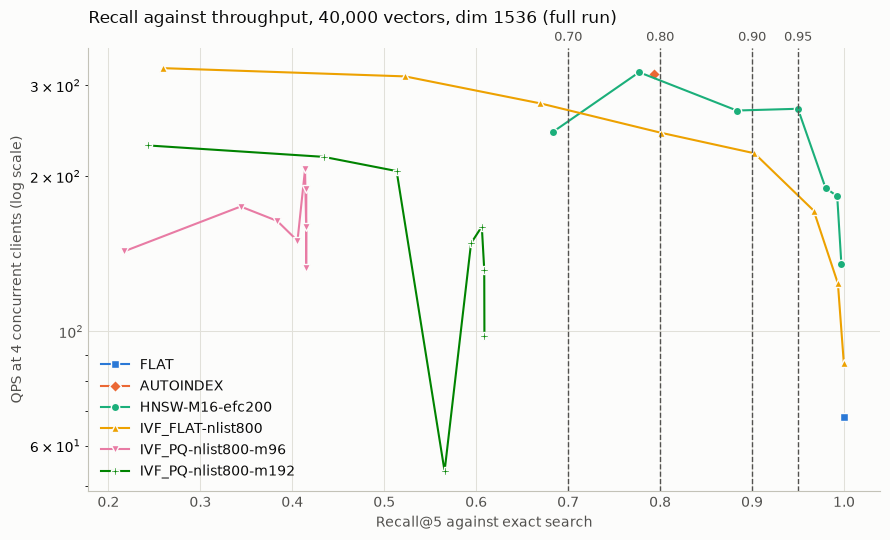

,config,search_param,search_value,recall_at_5,qps_c4
0,FLAT,None,NaN,1.000000,68.077014
1,AUTOINDEX,None,NaN,0.793188,315.971528
2,HNSW-M16-efc200,ef,10.0,0.683519,243.858947
3,HNSW-M16-efc200,ef,16.0,0.777143,318.311174
4,HNSW-M16-efc200,ef,32.0,0.883422,268.249345
5,HNSW-M16-efc200,ef,64.0,0.949863,270.347687
6,HNSW-M16-efc200,ef,128.0,0.979952,189.706941
7,HNSW-M16-efc200,ef,256.0,0.992575,182.977729
8,HNSW-M16-efc200,ef,512.0,0.997127,135.076390
9,IVF_FLAT-nlist800,nprobe,1.0,0.259370,324.157101


In [13]:
# ---- chart ----
# One colour per config, assigned by position in CONFIGS, so a config keeps its
# colour across runs. Markers repeat the identity for colour-blind readers and print.
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"]
MARKERS = ["s", "D", "o", "^", "v", "P"]
INK, MUTED, GRID, SURFACE = "#0b0b0b", "#52514e", "#e1e0d9", "#fcfcfb"

recall_fig, ax = plt.subplots(figsize=(9, 5.5), facecolor=SURFACE)
ax.set_facecolor(SURFACE)

for i, config in enumerate(CONFIGS):
    points_df = sweep_df[sweep_df["config"] == config["name"]].sort_values(RECALL_KEY)
    ax.plot(points_df[RECALL_KEY], points_df[SELECT_QPS], color=SERIES[i], marker=MARKERS[i],
            markersize=6, linewidth=1.5, markeredgecolor=SURFACE, markeredgewidth=1,
            label=config["name"])

for target in RECALL_TARGETS:
    ax.axvline(target, color=MUTED, linewidth=1, linestyle="--")
    ax.annotate(f"{target:.2f}", xy=(target, 1), xycoords=("data", "axes fraction"),
                xytext=(0, 3), textcoords="offset points", ha="center", va="bottom",
                color=MUTED, fontsize=9)

ax.set_yscale("log")
ax.set_xlabel(f"Recall@{TOP_K} against exact search", color=MUTED)
ax.set_ylabel(f"QPS at {PLAN['select_concurrency']} concurrent clients (log scale)", color=MUTED)
ax.set_title(f"Recall against throughput, {N_ROWS:,} vectors, dim {DIM} ({MODE} run)",
             color=INK, loc="left", fontsize=12, pad=18)
ax.grid(True, which="major", color=GRID, linewidth=0.75)
ax.set_axisbelow(True)
ax.tick_params(colors=MUTED, length=0)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
for side in ("left", "bottom"):
    ax.spines[side].set_color("#c3c2b7")
ax.legend(frameon=False, labelcolor=INK, loc="lower left")

recall_fig.tight_layout()
recall_fig.savefig(OUT_DIR / "recall_vs_qps.png", dpi=160, facecolor=SURFACE)
plt.show()

# The same points as a table: three of the series colours are low contrast on white.
display(sweep_df[["config", "search_param", "search_value", RECALL_KEY, SELECT_QPS]])

In [14]:
# ---- record the run ----
# common_params is everything that must match for two runs to be comparable. The
# MLflow cell reads it from this file, so it works from a fresh kernel.
COMMON_PARAMS = {
    "run_slug": RUN_SLUG, "run_mode": MODE, "git_sha": GIT_SHA,
    "source": f"{SOURCE_DATABASE}/{SOURCE_COLLECTION}", "n_rows": N_ROWS, "dim": DIM,
    "data_sha": DATA_SHA, "metric_type": METRIC_TYPE,
    "embedding_model": settings.embedding_model, "consistency_level": "Bounded",
    "query_set": "test_file.csv", "heldout_sha": HELDOUT_SHA, "sample_seed": SAMPLE_SEED,
    "n_recall_queries": len(RECALL_VECTORS), "n_timing_queries": len(TIMING_VECTORS),
    "top_k": TOP_K, "recall_targets": json.dumps(RECALL_TARGETS),
    "milvus_version": MILVUS_VERSION, "pymilvus_version": md.version("pymilvus"),
    "build_repeats": PLAN["build_repeats"], "latency_repeats": PLAN["latency_repeats"],
    "memory_cycles": PLAN["memory_cycles"],
    "concurrency": json.dumps(PLAN["concurrency"]), "qps_seconds": PLAN["qps_seconds"],
}

(OUT_DIR / "run_meta.json").write_text(json.dumps({
    "common_params": COMMON_PARAMS,
    "date_utc": TS,
    "select_concurrency": PLAN["select_concurrency"],
    "configs": CONFIGS,
    "deployed_index": SOURCE_INDEXES,
    "embedding_cost_usd": EMBEDDING_COST_USD,
    "segments_after_compaction": sorted(int(n) for n in build_df["segments"].unique()),
    "other_containers_running": OTHER_CONTAINERS,
    "docker_memory_limit_mb": DOCKER_MEMORY_LIMIT_MB,
    "machine": {"processor": platform.processor(), "logical_cpus": os.cpu_count(),
                "os": platform.platform(), "python": platform.python_version()},
}, indent=2, default=str), encoding="utf-8")

for file_name in ("pre_state.json", "source_index.json", "build.csv", "sweep.csv",
                  "head_to_head.csv", "recall_vs_qps.png", "run_meta.json"):
    path = OUT_DIR / file_name
    print(f"  {'ok' if path.exists() else '--'}  {path}")

  ok  data\eval\runs\index-types-full-20261105-1108\pre_state.json
  ok  data\eval\runs\index-types-full-20261105-1108\source_index.json
  ok  data\eval\runs\index-types-full-20261105-1108\build.csv
  ok  data\eval\runs\index-types-full-20261105-1108\sweep.csv
  ok  data\eval\runs\index-types-full-20261105-1108\head_to_head.csv
  ok  data\eval\runs\index-types-full-20261105-1108\recall_vs_qps.png
  ok  data\eval\runs\index-types-full-20261105-1108\run_meta.json


# 5) Log to MLflow

Runs after measuring and reads **only from `OUT_DIR`**, so it cannot disturb a timing and can
be re-run from a fresh kernel. Unlike the eval notebooks, a failure here **raises**: the
results are required in MLflow, and the next cell verifies that they arrived.

| Run | Name | Holds |
|---|---|---|
| Parent | `RUN_SLUG` | Common params, head-to-head metrics under `h2h/t<target>/<config>/`, all artifacts |
| Child, one per config | `HNSW-M16-efc200` | Build time, disk, RAM, load time, segments. Also recall and QPS stepped by search value, which charts them directly |
| Grandchild, one per search point | `HNSW-M16-efc200 ef=64` | Recall, latency, QPS at each concurrency |

Every run carries the common params and a `run_kind` tag, so a row is legible on its own.
Filter on `tags.comparable = 'true'` to exclude smoke runs.

In [15]:
# ---- log to MLflow ----
meta = json.loads((OUT_DIR / "run_meta.json").read_text(encoding="utf-8"))
common = meta["common_params"]
slug = common["run_slug"]
select_qps = f"qps_c{meta['select_concurrency']}"
recall_key = f"recall_at_{common['top_k']}"

logged_build = pd.read_csv(OUT_DIR / "build.csv")
logged_sweep = pd.read_csv(OUT_DIR / "sweep.csv")
logged_h2h = pd.read_csv(OUT_DIR / "head_to_head.csv")

mlflow.set_tracking_uri(MLFLOW_TRACKING_URI)
mlflow.set_experiment(MLFLOW_EXPERIMENT)
mlflow_client = MlflowClient()

# A re-run replaces this slug's earlier attempt rather than doubling it.
existing = mlflow.search_runs(experiment_names=[MLFLOW_EXPERIMENT],
                              filter_string=f"params.run_slug = '{slug}'")
for run_id in existing.get("run_id", []):
    mlflow_client.delete_run(run_id)


def numeric_metrics(row: pd.Series, skip: tuple = ()) -> dict:
    """The row's numeric cells, as MLflow metrics. NaN is left out, never logged."""
    return {key: float(value) for key, value in row.items()
            if key not in skip and not isinstance(value, (str, bool, np.bool_))
            and pd.notna(value)}


tags = {"phase": "1", "language": "th", "comparable": str(common["run_mode"] == "full").lower()}

with mlflow.start_run(run_name=slug) as parent:
    mlflow.log_params(common)
    mlflow.set_tags(tags | {"run_kind": "parent"})

    for row in logged_h2h.to_dict("records"):
        prefix = f"h2h/t{round(row['recall_target'] * 100)}/{row['config']}"
        mlflow.log_metrics({
            f"{prefix}/{key}": float(row[key])
            for key in (recall_key, f"{recall_key}_moe95", "latency_p95_ms", select_qps,
                        "build_seconds_median", "index_disk_mb", "ram_delta_mb")
            if pd.notna(row[key])
        } | {f"{prefix}/reached_target": float(bool(row["reached"])),
             f"{prefix}/at_sweep_floor": float(bool(row["at_sweep_floor"]))})

    for _, built in logged_build.iterrows():
        config_params = {"config": built["config"], "index_type": built["index_type"]} | {
            f"build_{key}": value for key, value in json.loads(built["build_params"]).items()
        }
        with mlflow.start_run(run_name=built["config"], nested=True):
            mlflow.log_params(common | config_params)
            mlflow.set_tags(tags | {"run_kind": "config"})
            mlflow.log_metrics(numeric_metrics(built))
            for step, seconds in enumerate(json.loads(built["build_seconds_all"])):
                mlflow.log_metric("build_seconds", seconds, step=step)

            points_of_config = logged_sweep[logged_sweep["config"] == built["config"]]
            for _, point in points_of_config.iterrows():
                has_param = pd.notna(point["search_param"])
                value = int(point["search_value"]) if has_param else 0

                # Stepped on the config run, so MLflow charts recall and QPS against
                # ef or nprobe without any extra work.
                mlflow.log_metric(recall_key, point[recall_key], step=value)
                mlflow.log_metric(select_qps, point[select_qps], step=value)

                point_name = (f"{built['config']} {point['search_param']}={value}"
                              if has_param else f"{built['config']} default")
                point_params = ({f"search_{point['search_param']}": value}
                                if has_param else {})
                with mlflow.start_run(run_name=point_name, nested=True):
                    mlflow.log_params(common | config_params | point_params)
                    mlflow.set_tags(tags | {"run_kind": "search_point"})
                    mlflow.log_metrics(numeric_metrics(point, skip=("search_value",)))

    for file_name in ("run_meta.json", "pre_state.json", "source_index.json", "build.csv",
                      "sweep.csv", "head_to_head.csv", "recall_vs_qps.png"):
        mlflow.log_artifact(str(OUT_DIR / file_name))

print(f"logged parent run {parent.info.run_id}")

🏃 View run FLAT default at: http://localhost:5000/#/experiments/7/runs/c89fcdd92a1b47e0b280b15766da8916
🧪 View experiment at: http://localhost:5000/#/experiments/7
🏃 View run FLAT at: http://localhost:5000/#/experiments/7/runs/73e70dea79a648e3bf327a0cd749a728
🧪 View experiment at: http://localhost:5000/#/experiments/7
🏃 View run AUTOINDEX default at: http://localhost:5000/#/experiments/7/runs/8f672886b97645bc95d88299ac7faf45
🧪 View experiment at: http://localhost:5000/#/experiments/7
🏃 View run AUTOINDEX at: http://localhost:5000/#/experiments/7/runs/f7dfe174f40e4d6982e6baeac4e7bc76
🧪 View experiment at: http://localhost:5000/#/experiments/7
🏃 View run HNSW-M16-efc200 ef=10 at: http://localhost:5000/#/experiments/7/runs/84dc24a9e664441b9b3a70fd65e47886
🧪 View experiment at: http://localhost:5000/#/experiments/7
🏃 View run HNSW-M16-efc200 ef=16 at: http://localhost:5000/#/experiments/7/runs/d35644f0f74b4f5fb762cd334512e112
🧪 View experiment at: http://localhost:5000/#/experiments/7
🏃 Vi

In [16]:
# ---- verify MLflow ----
# The record is a requirement, so "the call did not raise" is not enough. Read back.
logged_runs = mlflow.search_runs(experiment_names=[MLFLOW_EXPERIMENT],
                                 filter_string=f"params.run_slug = '{slug}'")

expected_runs = 1 + len(logged_build) + len(logged_sweep)
if len(logged_runs) != expected_runs:
    raise RuntimeError(f"MLflow holds {len(logged_runs)} runs for {slug}, expected {expected_runs}")
if not (logged_runs["status"] == "FINISHED").all():
    raise RuntimeError(f"unfinished runs:\n{logged_runs[['run_id', 'status']]}")

artifacts = {a.path for a in mlflow_client.list_artifacts(parent.info.run_id)}
missing_artifacts = {"run_meta.json", "build.csv", "sweep.csv", "head_to_head.csv",
                     "recall_vs_qps.png"} - artifacts
if missing_artifacts:
    raise RuntimeError(f"artifacts missing from MLflow: {sorted(missing_artifacts)}")

# A value read back from the server must equal the value on disk.
flat_on_disk = logged_sweep[logged_sweep["config"] == "FLAT"].iloc[0][recall_key]
flat_logged = logged_runs[logged_runs["tags.mlflow.runName"] == "FLAT default"] \
    .iloc[0][f"metrics.{recall_key}"]
if not np.isclose(flat_on_disk, flat_logged):
    raise RuntimeError(f"FLAT recall: {flat_on_disk} on disk, {flat_logged} in MLflow")

experiment_id = mlflow.get_experiment_by_name(MLFLOW_EXPERIMENT).experiment_id
link = f"{MLFLOW_TRACKING_URI}/#/experiments/{experiment_id}/runs/{parent.info.run_id}"
(OUT_DIR / "mlflow.json").write_text(json.dumps(
    {"run_id": parent.info.run_id, "experiment": MLFLOW_EXPERIMENT, "url": link,
     "runs_logged": len(logged_runs)}, indent=2), encoding="utf-8")

print(f"verified {len(logged_runs)} runs and {len(artifacts)} artifacts")
print(link)

verified 40 runs and 7 artifacts
http://localhost:5000/#/experiments/7/runs/af43343b67644213acbd4a1a7878aee0


In [17]:
# ---- markdown for the doc ----
# Paste these into docs/part_1/benchmark_index_types.md (R4).
def to_markdown(df: pd.DataFrame, digits: int = 3) -> str:
    def cell(value) -> str:
        if isinstance(value, (float, np.floating)):
            return "—" if pd.isna(value) else f"{value:.{digits}f}"
        return str(value)

    lines = ["| " + " | ".join(df.columns) + " |", "|" + "---|" * len(df.columns)]
    lines += ["| " + " | ".join(cell(v) for v in row) + " |" for row in df.itertuples(index=False)]
    return "\n".join(lines)


qps_columns = [f"qps_c{c}" for c in json.loads(common["concurrency"])]
print("### Build and footprint\n")
print(to_markdown(logged_build[["config", "build_seconds_median", "build_seconds_min",
                                "build_seconds_max", "index_disk_mb", "load_seconds",
                                "segments"]], digits=1))
print("\n### Memory\n")
print(to_markdown(logged_build[["config", "ram_delta_mb", "ram_delta_min_mb", "ram_delta_max_mb",
                                "ram_peak_delta_mb", "ram_cgroup_peak_mb",
                                "ram_after_sweep_delta_mb"]], digits=1))
print("\n### Sweep\n")
print(to_markdown(logged_sweep[["config", "search_param", "search_value", "recall_at_5",
                                "recall_at_5_moe95", "recall_at_10", "latency_p50_ms",
                                "latency_p95_ms", "latency_p99_ms", *qps_columns]], digits=3))
print("\n### Head-to-head: QPS by target\n")
print(to_markdown(qps_by_target(logged_h2h, select_qps), digits=0))
for target, group in logged_h2h.groupby("recall_target"):
    print(f"\n#### Recall@{common['top_k']} >= {target:.2f}\n")
    print(to_markdown(group[["config", "reached", "search_param", "search_value", recall_key,
                             f"{recall_key}_moe95", "latency_p95_ms", select_qps,
                             "at_sweep_floor"]]))
print("\n### Run log\n")
print(f"| {meta['date_utc']} | {slug} | {common['run_mode']} | {common['data_sha']} | "
      f"${meta['embedding_cost_usd']:.6f} | "
      f"{json.loads((OUT_DIR / 'mlflow.json').read_text(encoding='utf-8'))['url']} |")

### Build and footprint

| config | build_seconds_median | build_seconds_min | build_seconds_max | index_disk_mb | load_seconds | segments |
|---|---|---|---|---|---|---|
| FLAT | 0.3 | 0.3 | 22.1 | 0.0 | 1.7 | 2 |
| AUTOINDEX | 69.8 | 67.9 | 74.7 | 240.5 | 1.5 | 2 |
| HNSW-M16-efc200 | 48.0 | 46.9 | 61.9 | 239.9 | 1.5 | 2 |
| IVF_FLAT-nlist800 | 32.2 | 29.0 | 34.0 | 240.7 | 1.7 | 2 |
| IVF_PQ-nlist800-m96 | 117.3 | 99.1 | 124.6 | 13.0 | 1.3 | 2 |
| IVF_PQ-nlist800-m192 | 203.0 | 202.2 | 207.4 | 16.6 | 1.3 | 2 |

### Memory

| config | ram_delta_mb | ram_delta_min_mb | ram_delta_max_mb | ram_peak_delta_mb | ram_cgroup_peak_mb | ram_after_sweep_delta_mb |
|---|---|---|---|---|---|---|
| FLAT | 252.6 | 247.2 | 253.6 | 345.4 | 878.7 | 288.5 |
| AUTOINDEX | 256.9 | 255.6 | 257.8 | 500.0 | 918.8 | 295.7 |
| HNSW-M16-efc200 | 254.5 | 253.6 | 257.0 | 390.5 | 880.1 | 304.6 |
| IVF_FLAT-nlist800 | 259.7 | 258.1 | 262.4 | 689.6 | 802.9 | 311.3 |
| IVF_PQ-nlist800-m96 | 26.4 | 25.8 | 35.1 | 35.1 

## Clean up (optional)

The bench database takes up disk in MinIO, and old index builds linger until Milvus's garbage
collection runs. This drops only `restaurant_bench_db`, and only when you set the flag. The cached
vectors in `data/eval/index_bench/` are left in place.

In [18]:
# ---- clean up ----
DROP_BENCH_DATABASE = False

if DROP_BENCH_DATABASE:
    cleanup = bench_client()
    if cleanup.has_collection(BENCH_COLLECTION):
        cleanup.drop_collection(BENCH_COLLECTION)
    MilvusClient(uri=settings.milvus_uri).drop_database(BENCH_DATABASE)
    print(f"dropped {BENCH_DATABASE}")
else:
    print(f"kept {BENCH_DATABASE}")

kept restaurant_bench_db
